## 8. トピックスIII
### 8.5 加齢に伴って変化する基準範囲
#### 図8.2

Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
"collapsing to unique 'x' values"
Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
"collapsing to unique 'x' values"
Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
"collapsing to unique 'x' values"


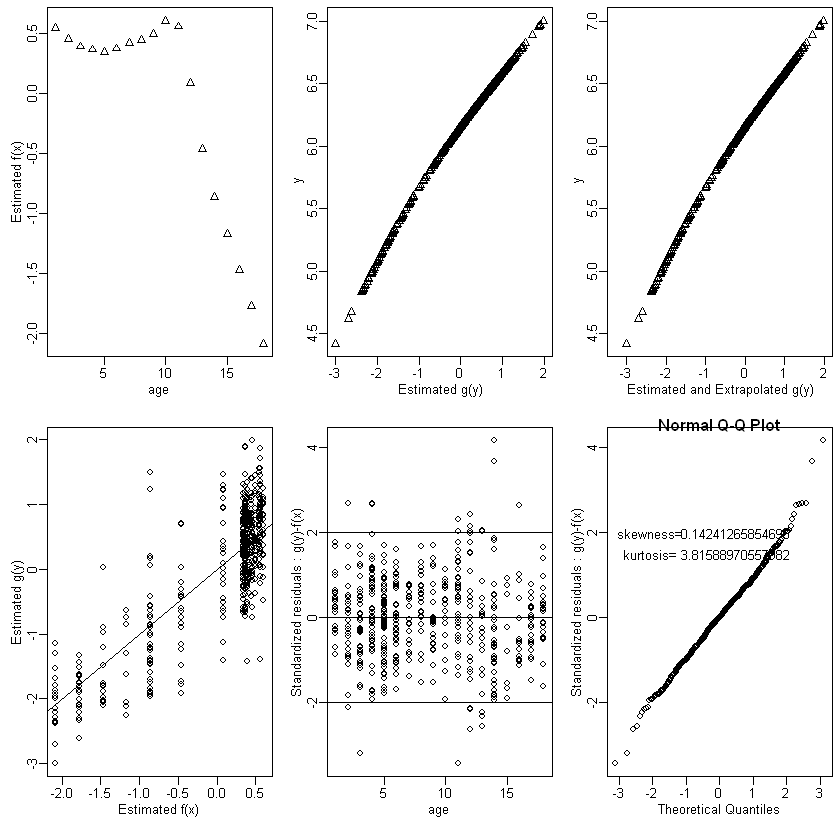

In [40]:
par(bg = "white")
#  S-PLUS program arrl.prg (No. 1 : Estimation procedures )   September 1996
#                            Programmed by
#
#                            Toshiro Tango
#                  Division of Theoretical Epidemiology
#                       Department of Epidemiology
#                     The Institute of Public Health
#                4-6-1 Shirokanedai, Minatoku, Tokyo, 108, Japan
#                        E-mail: tango@iph.go.jp
#
# ----------------------------------------------------------------
#                    (  README  FIRST )
#  1. Please read my paper carefully before using this program.
#  2. You are free to use this program for noncommercial purposes
#     even to modify it but please cite this original program
#
# Reference:
#  Tango T. Estimation of age-specific reference ranges via smoother AVAS.
#           Statistics in Medicine. 1998;17:1231-1243.
# -----------------------------------------------------------------
# +++++  Program for age-specific reference ranges via smoother AVAS
# +++++  This program uses log-transformed y-value
# +++++                          and exponentiates the results.
# +++++
# +++++  DATA vectors (ddx,ddy)
#
# ddx <- x-value vector (ex. age)
# ddy <- y-value vector (ex. foot length)
#
# +++++  THREE IMPORTANT PARAMETERS : (spanvar,cutm,cuth)
#
# cuth    <- 1.5  : default setting
#                   lower limit of data for upper tail extrapolation
# cutm    <- -1.5 : default setting
#                   upper limit of data for lower tail extrapolation
# spanvar <- 100  : default setting (= Cross Validatin method)
#                   span value for variance function smoother
#                   User specified span value
#                             should be within the range [0, 1)
#
# +++++  FOUR Parameters necessary for plotting data
#
# yname<- label of Y variable
# xname<- label of Y variable
# yup  <- upper limit of Y-axis
# ylow <- lower limit of Y-axis
#
# +++++  An example of execution
#    Data on 511 measurments of laboratory data ALP and age
#                     ( see Reference article)
#
#    ddx<- alp.age ; ddy<- alp ; cuth<- 1.5; cutm<- -1.5; spanvar<-100
#    xname<-" age (year)"; yname<-" ALP "
#    yup<-1500 ; ylow<- 0
#    source("refcurve1.s")
#    source("refcurve2.s")
#

library(acepack)

par(cex=0.5)
par(mar=c(4,3,0.5,0.5))
par(mfrow=c(2,3))
par(mgp=c(1.5,0.5,0))
ddx<-scan("./src/alpage.dat")/360
ddy<-scan("./src/alp.dat")
cuth<-1.5
cutm<- -1.5
spanvar<- 100
xname<- " age "
yname<- " ALP "
yup<- 1500
ylow<- 0
#
x    <- ddx
yval <- ddy
                                                   #
if (min(yval) == 0 ){  cons<-1 } else {  cons<-0 } # this part should be
yval<-log(yval+cons)                               # deleted when untransformed
                                                   # y-values are used
                                                   #
 if (spanvar<=1 ){  a<-avas(x,yval,span.var=spanvar)
                  } else {  a<-avas(x,yval) }
 plot(x,a$tx,pch=2,ylab="Estimated f(x)",xlab=xname)
 flag<-0
 hflag<-0
 lflag<-0
 nn<-length(x)
#
plot(a$ty,yval,pch=2,xlab=" Estimated g(y)",ylab=" y")
sdev<-sqrt(var(a$ty-a$tx))
m<-approx(a$ty,yval,a$tx)
if ( max(a$tx+1.96*as.numeric(sdev)) <= max(a$ty) ){
        h<-approx(a$ty,yval,a$tx+1.96*as.numeric(sdev))
    } else {
#        fit<-lsfit(a$ty[a$ty > cuth],yval[a$ty > cuth])
        aty<-a$ty[a$ty > cuth]
        fit<-lm(yval[a$ty > cuth] ~ aty+I(aty)^2 )
        deltax<-seq(max(a$ty),max(a$tx+2.10*as.numeric(sdev)),by=0.02)
        deltay<-fit$coef[1]+fit$coef[2]*deltax+fit$coef[3]*deltax^2
        h<-approx(c(a$ty,deltax),c(yval,deltay),a$tx+1.96*as.numeric(sdev))
        flag<-1
        hflag<-1}
if ( min(a$tx-1.96*as.numeric(sdev)) >= min(a$ty) ){
        lx<-approx(a$ty,yval,a$tx-1.96*as.numeric(sdev))
    } else {
#        fit<-lsfit(a$ty[a$ty < cutm],yval[a$ty < cutm])
        aty<-a$ty[a$ty < cutm]
        fit<-lm(yval[a$ty < cutm] ~ aty+I(aty)^2 )
        deltax2<-seq(min(a$tx-2.10*as.numeric(sdev)), min(a$ty),by=0.02)
        deltay2<-fit$coef[1]+fit$coef[2]*deltax2+fit$coef[3]*deltax2^2
        lx<-approx(c(deltax2,a$ty),c(deltay2,yval),a$tx-1.96*as.numeric(sdev))
        flag<-1
        lflag<-1}
 if (hflag==1 & lflag==0) {  plot(c(a$ty,deltax),c(yval,deltay),pch=2,
                       xlab=" Estimated and Extrapolated g(y)", ylab= "y")  }
 if (hflag==0 & lflag==1) {  plot(c(deltax2,a$ty),c(deltay2,yval),pch=2,
                        xlab=" Estimated and Extrapolated g(y)", ylab=" y" )  }
 if (hflag==1 & lflag==1) {
         plot(c(deltax2,a$ty,deltax),c(deltay2,yval,deltay),pch=2,
                        xlab=" Estimated and Extrapolated g(y)", ylab=" y" ) }
 plot(a$tx,a$ty,pch=1, xlab="Estimated f(x)", ylab="Estimated g(y)")
 abline(0,1)
 xs<-sort(x)
 mea<-m$y[sort.list(x)]
 upp<-h$y[sort.list(x)]
 lowx<-lx$y[sort.list(x)]
 plot(x,(a$ty-a$tx)/as.numeric(sdev),pch=1, xlab=xname,
                    ylab="Standardized residuals : g(y)-f(x)")
 abline(h=c(-2,0,2))
 tt<-(a$ty-a$tx)/as.numeric(sdev)
 qqnorm(tt,ylab="Standardized residuals : g(y)-f(x)")
 skew <- sqrt(nn)*sum(tt^3)/(sum(tt^2))^1.5
 kurt <- nn*sum(tt^4)/(sum(tt^2))^2
 text(-2,2,"skewness= ")
 text( 0.5,2,skew)
 text(-2,1.5,"kurtosis= ")
 text( 0.5,1.5,kurt)
#
# end of program No.1
# par(mfrow=c(1,2))
# plot(x,exp(yval)-cons,ylim=c(ylow,yup),xlab=xname,ylab=yname,pch=1) #: 4


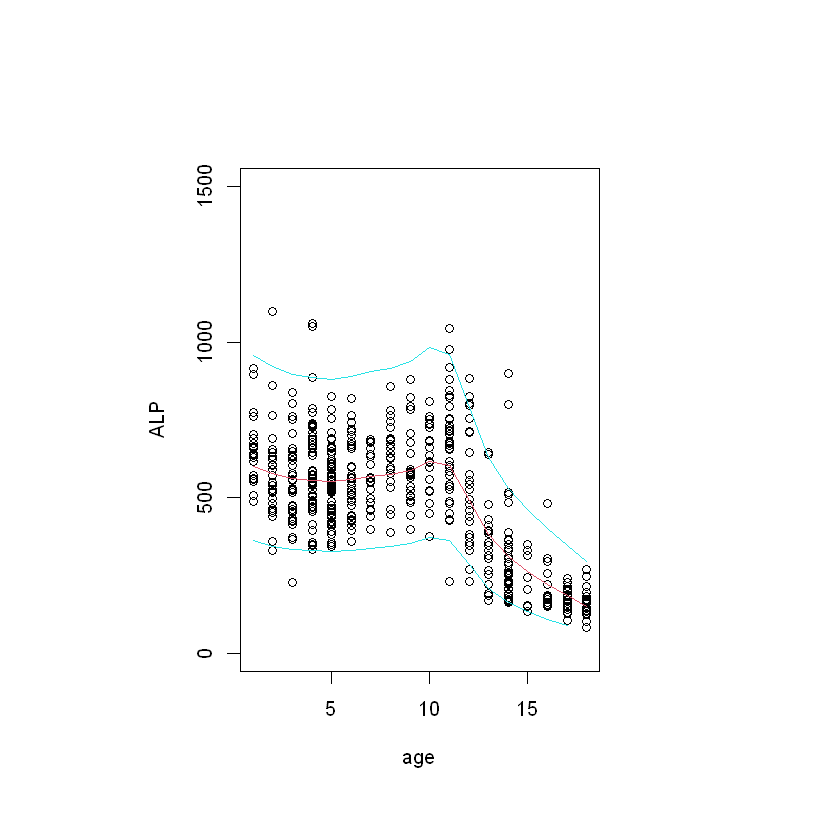

In [41]:
par(bg = "white")
# program arrl.prg (No.2: final plots)
#
#
par(mfrow=c(1,1))
par(mar=c(7,10,7,10))
nage<-length(unique(xs))
avasmat<-matrix(0,nage,4)
avasmat[,1]<-unique(xs)
avasmat[,2]<-unique(exp(lowx)-cons)  # :1
avasmat[,3]<-unique(exp(mea)-cons)   # :2
avasmat[,4]<-unique(exp(upp)-cons)   # ;3
# plot(x,exp(yval)-cons,ylim=c(ylow,yup),xlab=xname,ylab=yname,pch=1) #: 4
plot(x,exp(yval)-cons,ylim=c(ylow,yup),xlab=xname,ylab=yname,pch=1) #: 4
#
# ++++  When untransformed data are used, the above parts 1-4 should be
# ++++  replaced by the following parts 1-4.
#
# avasmat[,2]<-unique(lowx) # :1
# avasmat[,3]<-unique(mea)  # :2
# avasmat[,4]<-unique(upp)  # :3
# plot(x,yval,ylim=c(ylow,yup),xlab=xname,ylab=yname,pch=1) # :4
#
lines(avasmat[,1],avasmat[,2],col=5)
lines(avasmat[,1],avasmat[,3],col=18)
lines(avasmat[,1],avasmat[,4],col=5)
#
# end of program No.2
